<a href="https://colab.research.google.com/github/a15cardoso/neurodata_firstSemester_pythonWS/blob/python_workshop/task_reverse_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Electrophysiological Signal Decomposition & Parameter Estimation

### Overview
This notebook reverse engineers a 1D biological voltage trace (electrophysiological data). Given a raw voltage recording (`raw_data`), our objective is to systematically isolate and quantify its core generative components:

1. **Low-Frequency Baseline Drift:** Thermal/mechanical recording drift modeled as a sinusoid:
   $$\text{Drift}(t) = \text{offset} + A \sin(2\pi f t + \phi)$$
2. **Neural Action Potentials (Spikes):** Discrete voltage peaks identified at exact onset times.
3. **Spike Dynamics:** Modeled as an immediate voltage jump followed by first-order exponential decay:
   $$V(t) = V_0 e^{-t / \tau}$$
4. **Background Measurement Noise:** Gaussian noise ($\sigma_{\text{noise}}$) estimated from "quiet" segments.

### Output
At the end of execution, the notebook extracts biophysical parameters, generates standardized competition export files (`team_03_reconstruction.npz`, `README.md`, `evaluate_team.py`), and executes a Testing Module evaluating the simulation fit.

## Code Cell 1: Environment Setup & Data Loading

Please upload your dataset file (e.g., raw_data.npy or spike_data.npz):


Saving raw_data.npy to raw_data (3).npy

[Warning] Single array .npy file detected. Generated time vector 't' assuming fs = 10000 Hz.

File 'raw_data (3).npy' loaded successfully.
Array shapes: t=(10000,), raw_data=(10000,)
Signal Parameters: Duration=1.00s | Sampling Rate=10000.0Hz | Total Samples=10000
Summary Stats: Mean=0.077 | Std=0.734 | Min=-1.691 | Max=6.202


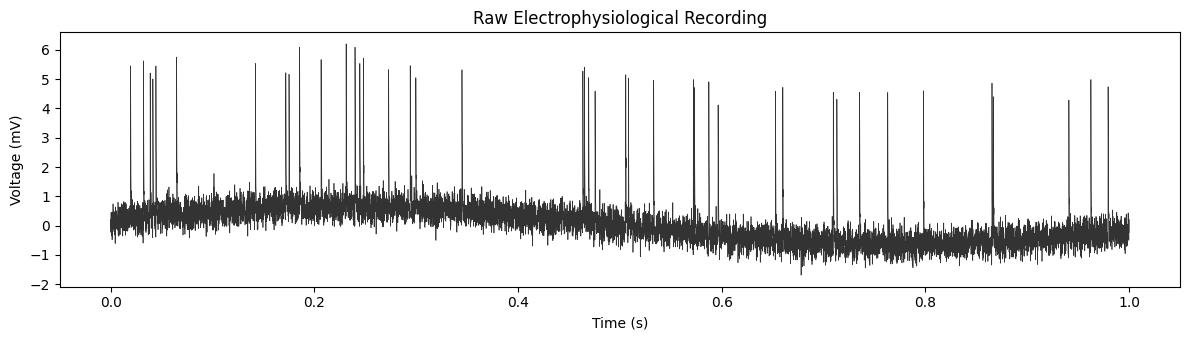

In [1]:
import io
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

# ==========================================
# 1. INTERACTIVE DATA UPLOAD
# ==========================================
print("Please upload your dataset file (e.g., raw_data.npy or spike_data.npz):")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file was uploaded. Please re-run the cell and select a valid file.")

# Extract filename and load binary data directly from memory
file_name = list(uploaded.keys())[0]
loaded_data = np.load(io.BytesIO(uploaded[file_name]), allow_pickle=True)

# Robust handling for .npy (single array) and .npz (dictionary of arrays) files
if file_name.endswith('.npz'):
    if 't' in loaded_data and 'raw_data' in loaded_data:
        t = loaded_data['t']
        raw_data = loaded_data['raw_data']
    else:
        # Fallback to key index if names differ
        keys = loaded_data.files
        raw_data = loaded_data[keys[0]]
        t = loaded_data[keys[1]] if len(keys) > 1 else np.arange(len(raw_data)) / 10000.0
else:
    # Assuming .npy containing raw 1D voltage trace
    raw_data = loaded_data
    fs_default = 10000.0
    t = np.arange(len(raw_data)) / fs_default
    print("\n[Warning] Single array .npy file detected. Generated time vector 't' assuming fs = 10000 Hz.")

print(f"\nFile '{file_name}' loaded successfully.")
print(f"Array shapes: t={t.shape}, raw_data={raw_data.shape}")

# Calculate basic temporal metrics
dt = np.median(np.diff(t))
fs = 1.0 / dt
duration_s = len(t) / fs
mean_val = np.mean(raw_data)
std_val = np.std(raw_data)

print(f"Signal Parameters: Duration={duration_s:.2f}s | Sampling Rate={fs:.1f}Hz | Total Samples={len(t)}")
print(f"Summary Stats: Mean={mean_val:.3f} | Std={std_val:.3f} | Min={raw_data.min():.3f} | Max={raw_data.max():.3f}")

# Plot raw signal
plt.figure(figsize=(12, 3.5))
plt.plot(t, raw_data, linewidth=0.5, color='black', alpha=0.8)
plt.xlabel("Time (s)")
plt.ylabel("Voltage (mV)")
plt.title("Raw Electrophysiological Recording")
plt.tight_layout()
plt.show()

## 2. Rising-Edge Spike Detection

To prevent counting a single multi-sample spike multiple times, we implement rising-edge boolean logic:
$$\text{Rising Edge}[i] = (V[i] > \text{Threshold}) \land \neg(V[i-1] > \text{Threshold})$$

This flags only the single index where the signal first crosses the detection threshold from below.

In [2]:
# ==========================================
# 2. SPIKE DETECTOR FUNCTION
# ==========================================
def detect_spikes(signal: np.ndarray, threshold: float) -> np.ndarray:
    """
    Identifies onset sample indices of spikes using rising-edge threshold crossing.
    """
    if len(signal) == 0:
        return np.array([], dtype=int)

    above_thresh = signal > threshold
    rising_edges = np.zeros(len(signal), dtype=bool)

    # Boundary handling for sample index 0
    rising_edges[0] = above_thresh[0]
    # Detect False-to-True transitions
    rising_edges[1:] = above_thresh[1:] & ~above_thresh[:-1]

    return np.where(rising_edges)[0]

## 3. Reverse Engineering Engine

This step executes three key operations:
1. **Quiet Baseline Masking:** Sets threshold at $\text{Mean} + 4\sigma$ to detect spikes, then masks out $15\text{ ms}$ post-onset (`TAIL_SAMPLES`) to isolate baseline data.
2. **Sinusoidal Drift Estimation:** Fits $a \sin(wt) + b \cos(wt) + c$ over candidate frequencies $f \in [0.02, 0.5]\text{ Hz}$ using Ordinary Least Squares (`np.linalg.lstsq`) on quiet samples. Selects the frequency minimizing Sum of Squared Errors (SSE), then converts to Amplitude ($A = \sqrt{a^2 + b^2}$) and Phase ($\phi = \operatorname{atan2}(b, a)$).
3. **Decay Dynamics & Noise Estimation:** Fits a log-linear model to the average spike shape across the first 6 samples post-onset to determine decay constant $\tau$. Estimates noise standard deviation ($\sigma_{\text{noise}}$), firing rate, and refractory period.

In [3]:
# ==========================================
# 3. REVERSE ENGINEERING & MODEL ESTIMATION
# ==========================================

# Step 1: Thresholding and Quiet Mask Creation
k_factor = 4.0
thr_real = mean_val + k_factor * std_val
spike_idx = detect_spikes(raw_data, thr_real)

TAIL_SAMPLES = int(0.015 * fs)  # 15 ms window
quiet_mask = np.ones(len(raw_data), dtype=bool)

for idx in spike_idx:
    quiet_mask[idx : idx + TAIL_SAMPLES] = False

print(f"Spikes Detected (Threshold = {thr_real:.3f}): {len(spike_idx)}")
print(f"Quiet Baseline Samples: {quiet_mask.sum()} / {len(quiet_mask)}")

# Step 2: Sinusoidal Drift Estimation (Grid Search + OLS)
t_quiet = t[quiet_mask]
x_quiet = raw_data[quiet_mask]

best_sse = np.inf
best_freq = None
best_coef = None

freq_candidates = np.arange(0.02, 0.5, 0.001)

for f in freq_candidates:
    w = 2 * np.pi * f * t_quiet
    X = np.column_stack([np.sin(w), np.cos(w), np.ones_like(t_quiet)])
    coef, _, _, _ = np.linalg.lstsq(X, x_quiet, rcond=None)
    sse = np.sum((x_quiet - X @ coef) ** 2)

    if sse < best_sse:
        best_sse = sse
        best_freq = f
        best_coef = coef

a, b, offset = best_coef
amp = np.hypot(a, b)
phase = np.arctan2(b, a)
drift_freq = best_freq

# Full reconstructed baseline drift vector
drift_fit = offset + amp * np.sin(2 * np.pi * drift_freq * t + phase)

# Step 3: Residual Analysis & Spike Decay
residual = raw_data - drift_fit
noise_sd = np.std(residual[quiet_mask])

heights = residual[spike_idx]
spike_amp = np.mean(heights)
spike_amp_sd = np.sqrt(max(np.var(heights) - noise_sd**2, 0.0))

# Log-linear fit for decay time constant (tau)
n_shape = 6
valid_spikes = [residual[i : i + n_shape] for i in spike_idx if i + n_shape <= len(raw_data)]
mean_shape = np.mean(valid_spikes, axis=0)

time_lags_samples = np.arange(n_shape)
log_shape = np.log(np.maximum(mean_shape, 1e-6))
slope, _ = np.polyfit(time_lags_samples, log_shape, 1)
tau_ms = (-1.0 / slope) / fs * 1000.0

# Firing Rate & Refractory Period
rate = len(spike_idx) / duration_s
refractory_ms = np.min(np.diff(spike_idx)) / fs * 1000.0 if len(spike_idx) > 1 else np.nan

# Save parameters table to local CSV
params = {
    "offset": offset,
    "amp": amp,
    "freq": drift_freq,
    "phase": phase,
    "noise_sd": noise_sd,
    "spike_amp": spike_amp,
    "spike_amp_sd": spike_amp_sd,
    "tau_ms": tau_ms,
    "rate": rate,
    "ref_ms": refractory_ms
}

coef_table = pd.Series(params, name="Estimated_Parameters")
coef_table.to_csv("coefficients.csv")

print("\n--- Estimated Parameters Summary ---")
print(coef_table.round(4))

Spikes Detected (Threshold = 3.015): 42
Quiet Baseline Samples: 5582 / 10000

--- Estimated Parameters Summary ---
offset          -0.0344
amp              0.6306
freq             0.4990
phase            1.4818
noise_sd         0.3444
spike_amp        5.0142
spike_amp_sd     0.0000
tau_ms           0.2958
rate            42.0000
ref_ms           1.1000
Name: Estimated_Parameters, dtype: float64


### Visual Verification

The figure below renders:
1. **Raw Signal vs. Fitted Drift:** Verifies baseline trajectory modeling.
2. **Spike Decay Dynamics:** Compares the mean spike waveform against the exponential fit ($V_0 e^{-t/\tau}$).
3. **Parameter Summary Table:** Displays all estimated values within the figure.

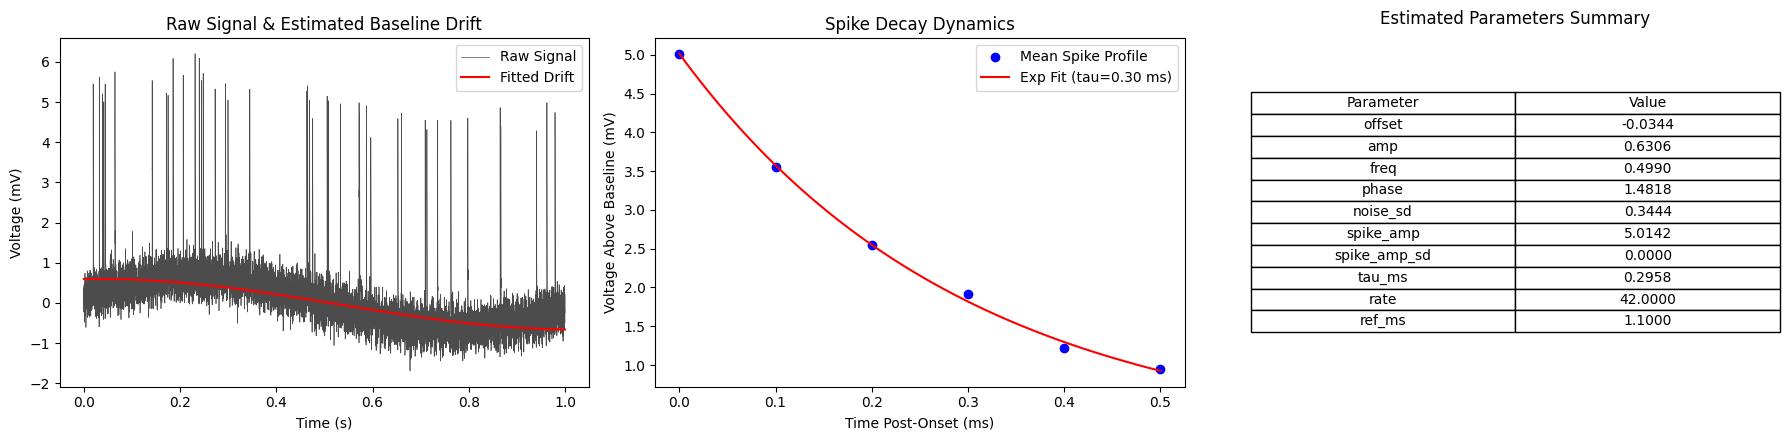

In [4]:
# ==========================================
# 4. VISUAL VERIFICATION & INLINE TABLE
# ==========================================
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

# Plot 1: Raw Signal vs Fitted Drift
ax[0].plot(t, raw_data, linewidth=0.5, label="Raw Signal", color="black", alpha=0.7)
ax[0].plot(t, drift_fit, color="red", linewidth=1.5, label="Fitted Drift")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Voltage (mV)")
ax[0].set_title("Raw Signal & Estimated Baseline Drift")
ax[0].legend(loc="upper right")

# Plot 2: Spike Decay Dynamics
lag_ms = np.arange(n_shape) / fs * 1000.0
fine_ms = np.linspace(0, lag_ms[-1], 100)
fit_decay = mean_shape[0] * np.exp(-fine_ms / tau_ms)

ax[1].plot(lag_ms, mean_shape, "o", color="blue", label="Mean Spike Profile")
ax[1].plot(fine_ms, fit_decay, color="red", label=f"Exp Fit (tau={tau_ms:.2f} ms)")
ax[1].set_xlabel("Time Post-Onset (ms)")
ax[1].set_ylabel("Voltage Above Baseline (mV)")
ax[1].set_title("Spike Decay Dynamics")
ax[1].legend(loc="upper right")

# Plot 3: Render Parameters Table
ax[2].axis('off')
table_data = [[param, f"{val:.4f}"] for param, val in coef_table.items()]
table = ax[2].table(
    cellText=table_data,
    colLabels=["Parameter", "Value"],
    cellLoc='center',
    loc='center'
)
table.scale(1, 1.3)
table.set_fontsize(10)
ax[2].set_title("Estimated Parameters Summary", pad=10)

plt.tight_layout()
plt.show()

## 5. Signal Reconstruction & Standardized Export (Part 1)

In accordance with the competition specifications:
1. We isolate structural components: baseline drift array and spike waveform train array.
2. We construct `reconstruction` exclusively from signal structures ($drift + spike\_signal$), leaving out noise realization as requested.
3. We export `team_03_reconstruction.npz` containing all 6 required keys and auto-generate `README.md`.

In [5]:
# ==========================================
# PART 1 — STANDARDIZED SUBMISSION FILE
# ==========================================

TEAM_ID = "03"  # Replace with your actual Team ID or Number

# 1. Component Reconstruction
drift_array = offset + amp * np.sin(2 * np.pi * drift_freq * t + phase)

# Pure Spike Waveform Train
spike_signal_array = np.zeros(len(t))
n_decay_samples = int((tau_ms / 1000.0) * fs * 5)
t_decay = np.arange(n_decay_samples) / fs

for idx in spike_idx:
    end_idx = min(idx + n_decay_samples, len(t))
    length = end_idx - idx
    spike_signal_array[idx:end_idx] += spike_amp * np.exp(-(t_decay[:length] * 1000.0) / tau_ms)

# Estimated Noise Realization (Seed 42)
np.random.seed(42)
noise_array = np.random.normal(0, noise_sd, size=len(t))

# Reconstructed Signal without noise
reconstruction_array = drift_array + spike_signal_array

# 2. Export Standardized NPZ File
output_npz_filename = f"team_{TEAM_ID}_reconstruction.npz"

np.savez(
    output_npz_filename,
    t=t,
    drift=drift_array,
    spike_signal=spike_signal_array,
    noise=noise_array,
    reconstruction=reconstruction_array,
    spike_indices=spike_idx
)

print(f"[OK] Standardized file saved: '{output_npz_filename}'")

# 3. Automatic README.md Generation
readme_content = f"""# Reverse-Engineering Project — Team {TEAM_ID}

## 1. Inferred Model & Parameters
- **Drift Offset:** {offset:.4f} mV
- **Drift Amplitude:** {amp:.4f} mV
- **Drift Frequency:** {drift_freq:.4f} Hz
- **Drift Phase:** {phase:.4f} rad
- **Spike Amplitude:** {spike_amp:.4f} mV
- **Spike Decay Constant (tau):** {tau_ms:.4f} ms
- **Noise Std Dev (sigma):** {noise_sd:.4f} mV
- **Firing Rate:** {rate:.2f} Hz

## 2. Assumptions
- The baseline drift is modeled as a low-frequency pure sinusoid: $A \\sin(2\\pi f t + \\phi) + \\text{{offset}}$.
- Spikes exhibit an immediate step voltage increase followed by a first-order exponential decay ($V_0 e^{{-t/\\tau}}$).
- Background noise is zero-mean additive white Gaussian noise (AWGN) estimated from quiet periods.
- Reconstructed signal contains structured components only ($drift + spikes$), omitting noise realization.

## 3. Detection & Reconstruction Method
1. **Spike Detection:** Rising-edge thresholding at $\\text{{Mean}} + 4\\sigma$.
2. **Quiet Baseline Masking:** Masking a 15 ms post-onset window for each detected spike.
3. **Drift Estimation:** Ordinary Least Squares (OLS) grid search across frequencies ($0.02 - 0.5$ Hz) on quiet baseline samples.
4. **Decay Dynamics:** Log-linear fitting on average spike profile to estimate $\\tau$.
"""

with open("README.md", "w") as f:
    f.write(readme_content)

print("[OK] 'README.md' generated successfully.")

[OK] Standardized file saved: 'team_03_reconstruction.npz'
[OK] 'README.md' generated successfully.


## 6. Evaluator Module (`evaluate_team.py` - Part 2)

We implement the required evaluation script `evaluate_team.py` containing the `evaluate(reference_file, candidate_file)` function interface to perform structural validation, metric computation, overlay plotting, and scoring.

In [8]:
%%writefile evaluate_team.py
import numpy as np
import matplotlib.pyplot as plt

def evaluate(reference_file: str, candidate_file: str) -> dict:
    """
    Evaluates a candidate team's reconstruction against the reference spike_data.npz.

    Inputs:
        reference_file: path to original spike_data.npz or raw_data.npy
        candidate_file: path to another team's reconstruction npz

    Output:
        dictionary containing validity, metrics, overlay_figure, and final_score.
    """
    # 1. Load Data
    ref_data = np.load(reference_file, allow_pickle=True)
    cand_data = np.load(candidate_file, allow_pickle=True)

    # Robust handling for reference file (supports both .npy arrays and .npz dicts)
    if isinstance(ref_data, np.ndarray):
        ref_raw = ref_data
        ref_t = np.arange(len(ref_raw)) / 10000.0
    elif hasattr(ref_data, 'files'):
        if 'raw_data' in ref_data:
            ref_raw = ref_data['raw_data']
        else:
            ref_raw = ref_data[ref_data.files[0]]

        if 't' in ref_data:
            ref_t = ref_data['t']
        else:
            ref_t = np.arange(len(ref_raw)) / 10000.0
    else:
        ref_raw = np.array(ref_data)
        ref_t = np.arange(len(ref_raw)) / 10000.0

    # 2. Structural Validity Checks on Candidate File
    required_keys = ['t', 'drift', 'spike_signal', 'noise', 'reconstruction', 'spike_indices']

    if not hasattr(cand_data, 'files'):
        return {
            "validity": False,
            "validity_details": "Candidate file is not a valid dictionary-based .npz file.",
            "final_score": 0.0
        }

    missing_keys = [k for k in required_keys if k not in cand_data]
    is_valid = len(missing_keys) == 0
    validity_details = "Passed all structural checks." if is_valid else f"Missing keys: {missing_keys}"

    if not is_valid:
        return {
            "validity": False,
            "validity_details": validity_details,
            "final_score": 0.0
        }

    cand_rec = cand_data['reconstruction']
    cand_t = cand_data['t']

    # 3. Numerical Metrics
    mse = float(np.mean((ref_raw - cand_rec) ** 2))
    rmse = float(np.sqrt(mse))
    mae = float(np.mean(np.abs(ref_raw - cand_rec)))

    # Pearson Correlation Coefficient
    corr_matrix = np.corrcoef(ref_raw, cand_rec)
    pearson_r = float(corr_matrix[0, 1])

    # Coefficient of Determination (R2 Score)
    ss_res = np.sum((ref_raw - cand_rec) ** 2)
    ss_tot = np.sum((ref_raw - np.mean(ref_raw)) ** 2)
    r2_score = float(1.0 - (ss_res / ss_tot))

    # 4. Final Score Calculation (0 - 100 Scale)
    score_corr = max(0.0, pearson_r) * 70.0
    score_r2 = max(0.0, r2_score) * 30.0
    final_score = round(score_corr + score_r2, 2)

    # 5. Overlay Figure (FIXED: set_ylabel instead of ylabel)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(ref_t, ref_raw, label="Reference Raw Signal", color="black", alpha=0.5, linewidth=0.8)
    ax.plot(cand_t, cand_rec, label="Candidate Reconstruction", color="crimson", alpha=0.8, linewidth=1.0)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Voltage (mV)")
    ax.set_title(f"Evaluation Overlay | Pearson R = {pearson_r:.4f} | R² = {r2_score:.4f}")
    ax.legend(loc="upper right")
    plt.tight_layout()

    # 6. Output Dictionary
    return {
        "validity": is_valid,
        "validity_details": validity_details,
        "metrics": {
            "MSE": mse,
            "RMSE": rmse,
            "MAE": mae,
            "Pearson_R": pearson_r,
            "R2_Score": r2_score
        },
        "overlay_figure": fig,
        "final_score": final_score
    }

Overwriting evaluate_team.py


## 7. Testing Module: Simulation Fit & Visual Verification

This module executes in-notebook validation to compare our synthesized simulation ($drift + spike\_signal + noise$) against the original `raw_data` trace.

      TESTING MODULE: SIMULATION FIT (TEAM 03)      
Validity Check : True (Passed all structural checks.)
Final Score    : 84.54 / 100
--------------------------------------------------
Numerical Metrics:
  - MSE         : 0.123961
  - RMSE        : 0.352082
  - MAE         : 0.281417
  - Pearson_R   : 0.877600
  - R2_Score    : 0.770166


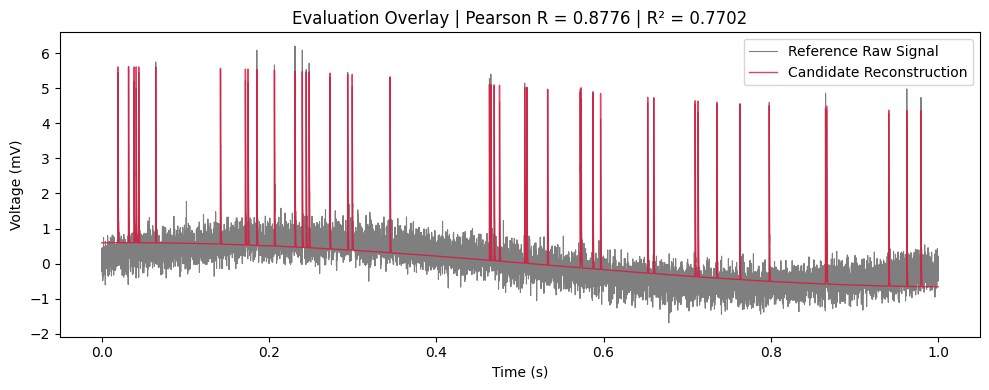

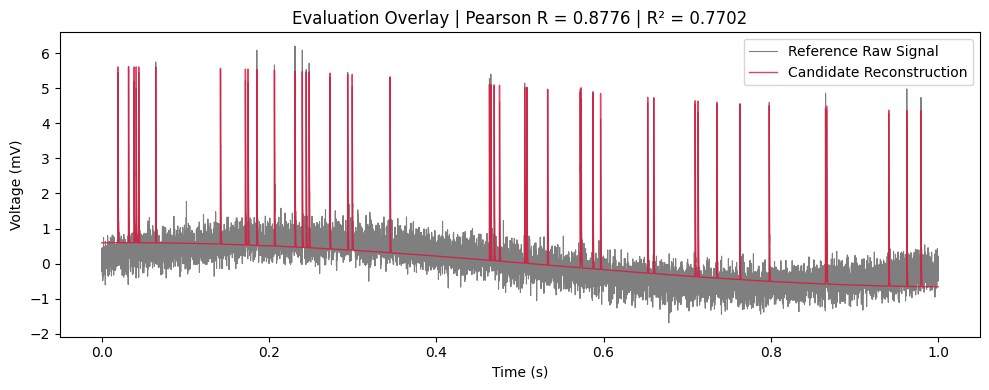

In [9]:
# ==========================================
# 7. IN-NOTEBOOK TESTING MODULE
# ==========================================
import importlib
import evaluate_team

# Force Python to reload evaluate_team from disk
importlib.reload(evaluate_team)

reference_path = file_name
candidate_path = f"team_{TEAM_ID}_reconstruction.npz"

eval_results = evaluate_team.evaluate(reference_path, candidate_path)

print("=" * 50)
print(f"      TESTING MODULE: SIMULATION FIT (TEAM {TEAM_ID})      ")
print("=" * 50)
print(f"Validity Check : {eval_results['validity']} ({eval_results['validity_details']})")
print(f"Final Score    : {eval_results['final_score']} / 100")
print("-" * 50)
print("Numerical Metrics:")
for metric_name, value in eval_results['metrics'].items():
    print(f"  - {metric_name:<12}: {value:.6f}")
print("=" * 50)

# Display comparative overlay plot
eval_results['overlay_figure']